
# E-commerce Sales & Revenue Analytics

## 1. Business Context

This project analyses historical transaction data from a UK-based online retailer to evaluate sales performance, product contribution, geographic markets, and customer purchasing behaviour.

The objective is to convert transaction-level data into business insights and visualizations that support evidence-based commercial decisions.

## 2. Business Problem

The retailer's transaction records contain information about products, quantities, prices, invoice dates, customers, and countries. This project will investigate how these records can be used to understand sales trends, identify revenue concentration, and highlight areas requiring further business investigation.

## 3. Project Objectives

- Evaluate recorded sales performance over time.
- Identify products contributing most to recorded sales.
- Compare sales performance across countries.
- Analyse order value and customer purchasing patterns.
- Develop meaningful KPIs and dashboard-style visualizations.
- Translate verified findings into actionable business recommendations.

## 4. Dataset

**Name:** Online Retail  
**Source:** UCI Machine Learning Repository  
**Period:** 1 December 2010 – 9 December 2011  
**Licence:** CC BY 4.0  
**Source URL:** https://archive.ics.uci.edu/dataset/352/online+retail

## 5. Analytical Approach

The analysis will cover data quality assessment, data preparation, KPI calculation, business-focused analysis, visualization, interpretation of findings, and evidence-based recommendations.

All conclusions will be based on the observed data. Correlations and descriptive patterns will not be treated as proof of causation.



## 2. Dataset Inspection

Before calculating business KPIs, we need to inspect the source dataset's structure, column names, data types, and sample records.

This initial inspection will help us understand how transactions are represented and identify potential data-quality issues without modifying the original dataset.


In [2]:

import pandas as pd

# Load the original Excel dataset
df = pd.read_excel("../data/Online Retail.xlsx")

# Display the first five transaction records
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom



## 3. Dataset Overview and Schema

Before defining business KPIs, we need to understand the dataset's size, column data types, and memory usage.

This step establishes the dataset's structural baseline and helps identify columns that may require type conversion or further validation during data preparation.

In [3]:

# Display the number of rows and columns
print(f"Number of rows: {df.shape[0]:,}")
print(f"Number of columns: {df.shape[1]}")

# Inspect column names, data types, non-null counts, and memory usage
df.info()


Number of rows: 541,909
Number of columns: 8
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB



## 4. Data Quality Assessment

Data quality affects the reliability of business KPIs and recommendations. Before cleaning the dataset, we will quantify missing values and duplicate records.

Missing customer identifiers may limit customer-level analysis, while missing product descriptions may affect product reporting. Duplicate records must be investigated before removal because repeated-looking transaction lines are not automatically errors.

The original dataset will remain unchanged during this assessment.


In [4]:

# Count missing values in each column
missing_values = df.isnull().sum()

# Calculate the percentage of missing values
missing_percentage = (missing_values / len(df)) * 100

# Summarize missing values
missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage (%)": missing_percentage.round(2)
})

print("Missing Values by Column:")
display(missing_summary)

# Count completely duplicated rows
duplicate_count = df.duplicated().sum()

print(f"\nCompletely duplicated rows: {duplicate_count:,}")


Missing Values by Column:


,Missing Values,Missing Percentage (%)
InvoiceNo,0,0.00
StockCode,0,0.00
Description,1454,0.27
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
CustomerID,135080,24.93
Country,0,0.00



Completely duplicated rows: 5,268



## 5. Transaction Anomaly Analysis

Retail transaction data may contain cancelled invoices, returned items, zero or negative quantities, and non-positive unit prices.

These records require investigation before calculating revenue and order-related KPIs. We will quantify the affected records first and establish transparent treatment rules based on the observed data.

No records will be removed or modified in this step.


In [5]:

# Identify cancelled invoices
cancelled_invoice_mask = df["InvoiceNo"].astype(str).str.startswith("C")

# Identify unusual quantities and prices
negative_quantity_mask = df["Quantity"] < 0
zero_quantity_mask = df["Quantity"] == 0
zero_price_mask = df["UnitPrice"] == 0
negative_price_mask = df["UnitPrice"] < 0

# Summarize the affected records
anomaly_summary = pd.DataFrame({
    "Anomaly": [
        "Cancelled invoice rows",
        "Negative quantity rows",
        "Zero quantity rows",
        "Zero unit price rows",
        "Negative unit price rows"
    ],
    "Affected Rows": [
        cancelled_invoice_mask.sum(),
        negative_quantity_mask.sum(),
        zero_quantity_mask.sum(),
        zero_price_mask.sum(),
        negative_price_mask.sum()
    ],
    "Unique Invoices": [
        df.loc[cancelled_invoice_mask, "InvoiceNo"].nunique(),
        df.loc[negative_quantity_mask, "InvoiceNo"].nunique(),
        df.loc[zero_quantity_mask, "InvoiceNo"].nunique(),
        df.loc[zero_price_mask, "InvoiceNo"].nunique(),
        df.loc[negative_price_mask, "InvoiceNo"].nunique()
    ]
})

display(anomaly_summary)


,Anomaly,Affected Rows,Unique Invoices
0,Cancelled invoice rows,9288,3836
1,Negative quantity rows,10624,5172
2,Zero quantity rows,0,0
3,Zero unit price rows,2515,2155
4,Negative unit price rows,2,2



## 6. Review of Anomalous Transactions

Aggregate anomaly counts show how frequently unusual records occur, but they do not explain their meaning.

We will inspect negative-price transactions, sample negative-quantity transactions, and zero-price transactions to understand their characteristics before deciding how they should affect the sales KPIs.

These records will remain unchanged during this investigation.


In [6]:

# Inspect all records with negative unit prices
print("Records with Negative Unit Prices:")
display(
    df.loc[df["UnitPrice"] < 0, [
        "InvoiceNo", "StockCode", "Description",
        "Quantity", "UnitPrice", "CustomerID", "Country"
    ]]
)

# Inspect a sample of negative-quantity transactions
print("\nSample Records with Negative Quantities:")
display(
    df.loc[df["Quantity"] < 0, [
        "InvoiceNo", "StockCode", "Description",
        "Quantity", "UnitPrice", "InvoiceDate"
    ]].head(10)
)

# Inspect a sample of zero-price transactions
print("\nSample Records with Zero Unit Prices:")
display(
    df.loc[df["UnitPrice"] == 0, [
        "InvoiceNo", "StockCode", "Description",
        "Quantity", "UnitPrice", "InvoiceDate"
    ]].head(10)
)


Records with Negative Unit Prices:


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,-11062.06,NaN,United Kingdom



Sample Records with Negative Quantities:


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,InvoiceDate
141,C536379,D,Discount,-1,27.50,2010-12-01 09:41:00
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,4.65,2010-12-01 09:49:00
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,1.65,2010-12-01 10:24:00
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,0.29,2010-12-01 10:24:00
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,0.29,2010-12-01 10:24:00
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,0.29,2010-12-01 10:24:00
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,3.45,2010-12-01 10:24:00
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,1.65,2010-12-01 10:24:00
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,1.65,2010-12-01 10:24:00
939,C536506,22960,JAM MAKING SET WITH JARS,-6,4.25,2010-12-01 12:38:00



Sample Records with Zero Unit Prices:


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,InvoiceDate
622,536414,22139,NaN,56,0.0,2010-12-01 11:52:00
1970,536545,21134,NaN,1,0.0,2010-12-01 14:32:00
1971,536546,22145,NaN,1,0.0,2010-12-01 14:33:00
1972,536547,37509,NaN,1,0.0,2010-12-01 14:33:00
1987,536549,85226A,NaN,1,0.0,2010-12-01 14:34:00
1988,536550,85044,NaN,1,0.0,2010-12-01 14:34:00
2024,536552,20950,NaN,1,0.0,2010-12-01 14:34:00
2025,536553,37461,NaN,3,0.0,2010-12-01 14:35:00
2026,536554,84670,NaN,23,0.0,2010-12-01 14:35:00
2406,536589,21777,NaN,-10,0.0,2010-12-01 16:50:00



## 7. Overlapping Anomalies and Duplicate Impact

Transaction anomalies may overlap, so their counts must not be added together as if they were independent. Exact duplicate rows may also affect recorded sales value and transaction counts.

This step measures the overlap between cancellation invoices and negative quantities, and quantifies the potential effect of exact duplicate rows on line-item sales value.

These measurements will inform the cleaning policy; no records will be removed at this stage.


In [7]:

# Measure overlap between cancellation invoices and negative quantities
print("Cancellation and Quantity Overlap")
print(f"Cancellation invoice rows: {cancelled_invoice_mask.sum():,}")
print(f"Negative quantity rows: {negative_quantity_mask.sum():,}")
print(
    "Rows meeting both conditions: "
    f"{(cancelled_invoice_mask & negative_quantity_mask).sum():,}"
)
print(
    "Negative quantity rows without a C-prefixed invoice: "
    f"{(negative_quantity_mask & ~cancelled_invoice_mask).sum():,}"
)

# Calculate recorded line-item values
df["LineValue"] = df["Quantity"] * df["UnitPrice"]

# Identify exact duplicate rows using the original eight columns
original_columns = [
    "InvoiceNo", "StockCode", "Description", "Quantity",
    "InvoiceDate", "UnitPrice", "CustomerID", "Country"
]
duplicate_mask = df.duplicated(subset=original_columns)

# Quantify the potential effect of removing later duplicate occurrences
duplicate_rows = df.loc[duplicate_mask]

print("\nExact Duplicate Impact")
print(f"Duplicate rows beyond the first occurrence: {len(duplicate_rows):,}")
print(f"Line-item value of those rows: {duplicate_rows['LineValue'].sum():,.2f}")
print(
    "Absolute line-item value of those rows: "
    f"{duplicate_rows['LineValue'].abs().sum():,.2f}"
)


Cancellation and Quantity Overlap
Cancellation invoice rows: 9,288
Negative quantity rows: 10,624
Rows meeting both conditions: 9,288
Negative quantity rows without a C-prefixed invoice: 1,336

Exact Duplicate Impact
Duplicate rows beyond the first occurrence: 5,268
Line-item value of those rows: 21,740.98
Absolute line-item value of those rows: 27,406.50



## 8. Data Preparation Rules

The primary sales analysis will use a clearly defined subset of the original transaction records.

- Exclude invoices whose invoice numbers begin with `C`.
- Include only records with positive quantities and positive unit prices in the primary gross-sales view.
- Retain records with missing customer IDs or product descriptions when they otherwise meet the sales criteria.
- Preserve exact duplicate rows initially. Their legitimacy cannot be established from matching values alone, so their impact will be assessed separately.
- Keep the original dataset unchanged and create a separate DataFrame for analysis.

**Metric definition:** Gross recorded sales are calculated as the sum of quantity multiplied by unit price for eligible positive-quantity sales lines. This measure excludes recorded returns, cancellations, and non-positive prices; it is not net revenue, profit, or cash collected.

These rules prioritize consistency and transparency. Their effects and limitations will be documented in the final report.


In [8]:

# Define eligible records for the primary gross-sales analysis
sales_mask = (
    ~cancelled_invoice_mask
    & (df["Quantity"] > 0)
    & (df["UnitPrice"] > 0)
)

# Create a separate DataFrame; preserve the original df
sales_df = df.loc[sales_mask].copy()

# Calculate gross recorded line-item sales value
sales_df["LineValue"] = sales_df["Quantity"] * sales_df["UnitPrice"]

# Report the effect of the selection
print(f"Original records: {len(df):,}")
print(f"Eligible sales records: {len(sales_df):,}")
print(f"Excluded records: {len(df) - len(sales_df):,}")
print(f"Gross recorded sales: {sales_df['LineValue'].sum():,.2f}")
print(f"Distinct invoices: {sales_df['InvoiceNo'].nunique():,}")
print(f"Missing customer IDs in sales data: {sales_df['CustomerID'].isna().sum():,}")
print(f"Missing descriptions in sales data: {sales_df['Description'].isna().sum():,}")


Original records: 541,909
Eligible sales records: 530,104
Excluded records: 11,805
Gross recorded sales: 10,666,684.54
Distinct invoices: 19,960
Missing customer IDs in sales data: 132,220
Missing descriptions in sales data: 0



## 9. Sales Dataset Validation

Before interpreting business performance, we need to validate the prepared sales dataset.

This validation checks the date range, remaining exact duplicates, sales-value consistency, and missing values. These checks help establish whether the dataset is ready for KPI calculations and dashboard development.

The validation does not automatically remove records or change the current sales-selection policy.


In [ ]:

# Check the date range
print("Sales Date Range:")
print(f"First transaction: {sales_df['InvoiceDate'].min()}")
print(f"Last transaction:  {sales_df['InvoiceDate'].max()}")

# Check exact duplicates within eligible sales records
sales_duplicates = sales_df.duplicated(subset=original_columns).sum()
print(f"\nExact duplicate rows in sales data: {sales_duplicates:,}")

# Validate line-item sales calculations
calculated_sales = (sales_df["Quantity"] * sales_df["UnitPrice"]).sum()
stored_sales = sales_df["LineValue"].sum()

print(f"\nCalculated gross sales: {calculated_sales:,.2f}")
print(f"Stored gross sales:     {stored_sales:,.2f}")
print(f"Values match:           {calculated_sales == stored_sales}")

# Check for invalid values remaining under the current rules
print("\nValidation Checks:")
print(f"Non-positive quantities: {(sales_df['Quantity'] <= 0).sum():,}")
print(f"Non-positive unit prices: {(sales_df['UnitPrice'] <= 0).sum():,}")
print(f"Missing invoice dates: {sales_df['InvoiceDate'].isna().sum():,}")
print(f"Missing product descriptions: {sales_df['Description'].isna().sum():,}")



Sales Date Range:
First transaction: 2010-12-01 08:26:00
Last transaction:  2011-12-09 12:50:00

Exact duplicate rows in sales data: 5,226

Calculated gross sales: 10,666,684.54
Stored gross sales:     10,666,684.54
Values match:           True

Validation Checks:
Non-positive quantities: 0
Non-positive unit prices: 0
Missing invoice dates: 0
Missing product descriptions: 0



## 10. Duplicate Impact Assessment

Exact duplicate records remain in the prepared sales dataset. Before deciding whether to exclude them, we will quantify their effect on gross recorded sales and distinct invoice counts.

Identical transaction lines may be duplicated records, but matching values alone do not prove that they are erroneous. The comparison will therefore be reported as a sensitivity analysis rather than treated as definitive proof that all duplicate occurrences should be removed.


In [10]:

# Identify repeated occurrences using the original source columns
sales_duplicate_mask = sales_df.duplicated(subset=original_columns)

# Create a comparison dataset without later exact duplicate occurrences
sales_deduplicated = sales_df.loc[~sales_duplicate_mask].copy()

# Compare key sales metrics
duplicate_comparison = pd.DataFrame({
    "Metric": [
        "Sales records",
        "Distinct invoices",
        "Gross recorded sales"
    ],
    "With duplicates": [
        len(sales_df),
        sales_df["InvoiceNo"].nunique(),
        sales_df["LineValue"].sum()
    ],
    "Without duplicate occurrences": [
        len(sales_deduplicated),
        sales_deduplicated["InvoiceNo"].nunique(),
        sales_deduplicated["LineValue"].sum()
    ]
})

display(duplicate_comparison)


,Metric,With duplicates,Without duplicate occurrences
0,Sales records,5.301040e+05,5.248780e+05
1,Distinct invoices,1.996000e+04,1.996000e+04
2,Gross recorded sales,1.066668e+07,1.064211e+07



## 11. Final Analysis Dataset

The duplicate sensitivity analysis shows that removing later exact duplicate occurrences reduces gross recorded sales without changing the number of distinct invoices.

For the primary analysis, we will use the dataset with later exact duplicate occurrences removed. This is an analytical assumption rather than confirmation that every repeated record is erroneous. Results will be interpreted with this limitation documented.

The original source data and the prepared dataset containing duplicates remain available for comparison.


In [11]:

# Create the primary analysis dataset from the deduplicated sales records
analysis_df = sales_deduplicated.copy()

# Validate the resulting dataset
print(f"Primary analysis records: {len(analysis_df):,}")
print(f"Distinct invoices: {analysis_df['InvoiceNo'].nunique():,}")
print(f"Gross recorded sales: {analysis_df['LineValue'].sum():,.2f}")
print(
    "Remaining exact duplicate rows: "
    f"{analysis_df.duplicated(subset=original_columns).sum():,}"
)

# Confirm that the primary dataset contains only eligible sales lines
print(
    "Non-positive quantities: "
    f"{(analysis_df['Quantity'] <= 0).sum():,}"
)
print(
    "Non-positive unit prices: "
    f"{(analysis_df['UnitPrice'] <= 0).sum():,}"
)


Primary analysis records: 524,878
Distinct invoices: 19,960
Gross recorded sales: 10,642,110.80
Remaining exact duplicate rows: 0
Non-positive quantities: 0
Non-positive unit prices: 0



## 12. Baseline Business KPIs

Key performance indicators translate transaction records into measures that business stakeholders can use to assess sales performance.

Before analysing trends or comparing products and markets, we will reconcile the recorded sales total and calculate baseline metrics for sales value, order volume, units sold, and average order value.

All KPIs will use the validated primary analysis dataset and the documented transaction-selection rules.


In [12]:

# Reconcile the sales total across the prepared datasets
print("Sales Total Reconciliation")
print(f"Deduplicated dataset total: {sales_deduplicated['LineValue'].sum():,.2f}")
print(f"Primary analysis total:     {analysis_df['LineValue'].sum():,.2f}")
print(
    "Difference:                 "
    f"{analysis_df['LineValue'].sum() - sales_deduplicated['LineValue'].sum():,.2f}"
)

# Calculate baseline KPIs
gross_recorded_sales = analysis_df["LineValue"].sum()
order_count = analysis_df["InvoiceNo"].nunique()
units_sold = analysis_df["Quantity"].sum()
average_order_value = gross_recorded_sales / order_count

baseline_kpis = pd.DataFrame({
    "KPI": [
        "Gross recorded sales",
        "Distinct orders",
        "Units sold",
        "Average order value"
    ],
    "Value": [
        gross_recorded_sales,
        order_count,
        units_sold,
        average_order_value
    ]
})

display(baseline_kpis)


Sales Total Reconciliation
Deduplicated dataset total: 10,642,110.80
Primary analysis total:     10,642,110.80
Difference:                 0.00


,KPI,Value
0,Gross recorded sales,1.064211e+07
1,Distinct orders,1.996000e+04
2,Units sold,5.572420e+06
3,Average order value,5.331719e+02



## 13. Monthly Sales Performance

Monthly sales analysis helps stakeholders identify changes in recorded sales value and order volume over time.

We will aggregate the validated transaction records by calendar month and calculate gross recorded sales, distinct orders, units sold, and average order value. Comparing these metrics will help distinguish changes in sales value from changes in purchasing activity.

Monthly patterns are descriptive evidence; they do not establish the causes of sales increases or decreases.


In [15]:

display(
    monthly_sales.round({
        "Gross_Sales": 2,
        "Average_Order_Value": 2
    })
)


,Month,Gross_Sales,Distinct_Orders,Units_Sold,Average_Order_Value
0,2010-12,821452.73,1559,358019,526.91
1,2011-01,689811.61,1086,387099,635.19
2,2011-02,522545.56,1100,282934,475.04
3,2011-03,716215.26,1454,376599,492.58
4,2011-04,536968.49,1246,307953,430.95
5,2011-05,769296.61,1681,395001,457.64
6,2011-06,760547.01,1533,388511,496.12
7,2011-07,718076.12,1475,399693,486.83
8,2011-08,757841.38,1361,421020,556.83
9,2011-09,1056435.19,1837,569573,575.09



## 14. Monthly Revenue Trend

A monthly revenue trend chart helps stakeholders identify periods of higher and lower recorded sales value.

The visualization will show gross recorded sales by month. Because the first and last months in the dataset are incomplete, those periods must be interpreted cautiously when comparing monthly performance.


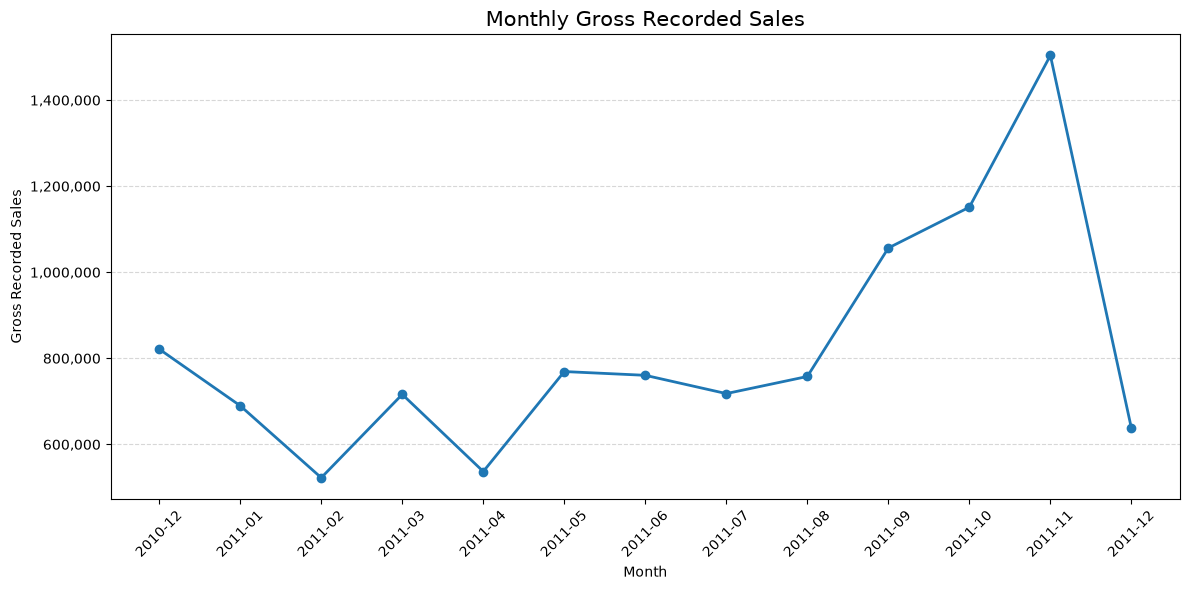

In [18]:

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# Convert monthly periods to readable labels
months = monthly_sales["Month"].astype(str)

plt.figure(figsize=(12, 6))
plt.plot(
    months,
    monthly_sales["Gross_Sales"],
    marker="o",
    linewidth=2
)

plt.title("Monthly Gross Recorded Sales", fontsize=15)
plt.xlabel("Month")
plt.ylabel("Gross Recorded Sales")

# Format values with thousands separators
plt.gca().yaxis.set_major_formatter(
    mtick.StrMethodFormatter("{x:,.0f}")
)

plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()



## 15. Monthly Order Volume

Revenue can change because of changes in order volume, average order value, or both. Analysing monthly order counts separately helps distinguish purchasing activity from changes in the value of recorded sales.

The chart will show distinct eligible invoices by month. Partial months will be interpreted cautiously.


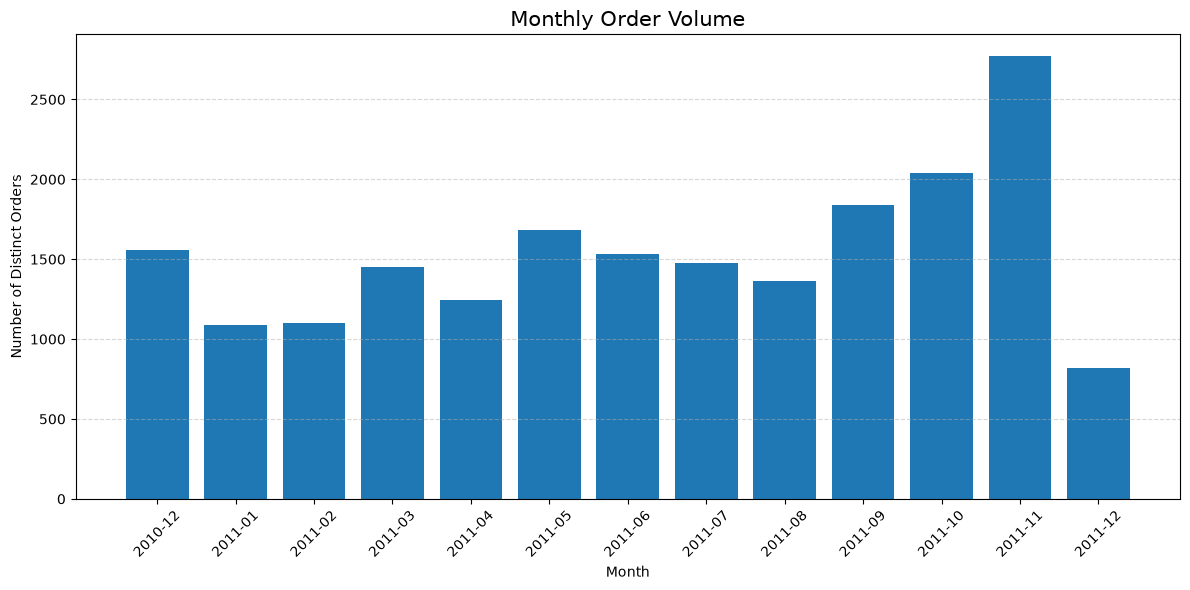

In [19]:

plt.figure(figsize=(12, 6))

plt.bar(
    monthly_sales["Month"].astype(str),
    monthly_sales["Distinct_Orders"]
)

plt.title("Monthly Order Volume", fontsize=15)
plt.xlabel("Month")
plt.ylabel("Number of Distinct Orders")
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()



## 16. Average Order Value Analysis

Average order value (AOV) measures the average gross recorded sales value per eligible invoice.

Analysing AOV alongside order volume helps distinguish changes in purchasing activity from changes in the value of each order. This is a descriptive comparison and does not establish why customer spending patterns changed.


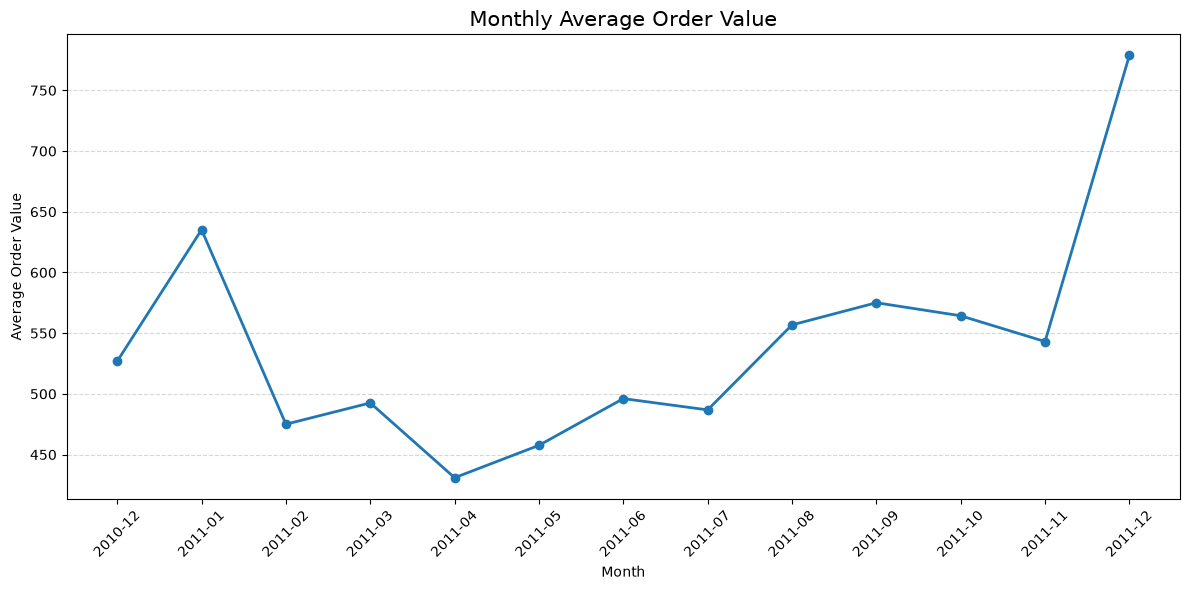

In [20]:

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_sales["Month"].astype(str),
    monthly_sales["Average_Order_Value"],
    marker="o",
    linewidth=2
)

plt.title("Monthly Average Order Value", fontsize=15)
plt.xlabel("Month")
plt.ylabel("Average Order Value")
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()



## 17. Product Performance Analysis

Product-level analysis helps identify which products contribute most to gross recorded sales and which generate higher sales volumes.

We will aggregate eligible sales records by product, calculate gross recorded sales, units sold, and distinct orders, and identify the top 10 products by recorded sales value.

These metrics describe historical sales performance. They do not measure profitability because product costs and margins are unavailable.


In [21]:

# Aggregate eligible sales by product
product_sales = (
    analysis_df.groupby(["StockCode", "Description"])
    .agg(
        Gross_Sales=("LineValue", "sum"),
        Units_Sold=("Quantity", "sum"),
        Distinct_Orders=("InvoiceNo", "nunique")
    )
    .reset_index()
    .sort_values("Gross_Sales", ascending=False)
)

# Select the top 10 products by gross recorded sales
top_10_products = product_sales.head(10).copy()

# Calculate each product's share of total gross recorded sales
top_10_products["Sales_Share_Percent"] = (
    top_10_products["Gross_Sales"]
    / analysis_df["LineValue"].sum()
    * 100
)

display(top_10_products.round({
    "Gross_Sales": 2,
    "Sales_Share_Percent": 2
}))


,StockCode,Description,Gross_Sales,Units_Sold,Distinct_Orders,Sales_Share_Percent
4150,DOT,DOTCOM POSTAGE,206248.77,706,706,1.94
1262,22423,REGENCY CAKESTAND 3 TIER,174156.54,13851,1988,1.64
2590,23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995,1,1.58
3773,85123A,WHITE HANGING HEART T-LIGHT HOLDER,104284.24,37580,2189,0.98
2669,47566,PARTY BUNTING,99445.23,18283,1685,0.93
3761,85099B,JUMBO BAG RED RETROSPOT,94159.81,48371,2089,0.88
2045,23166,MEDIUM CERAMIC TOP STORAGE JAR,81700.92,78033,247,0.77
4153,POST,POSTAGE,78101.88,3150,1126,0.73
4151,M,Manual,77750.27,6984,289,0.73
1951,23084,RABBIT NIGHT LIGHT,66870.03,30739,994,0.63


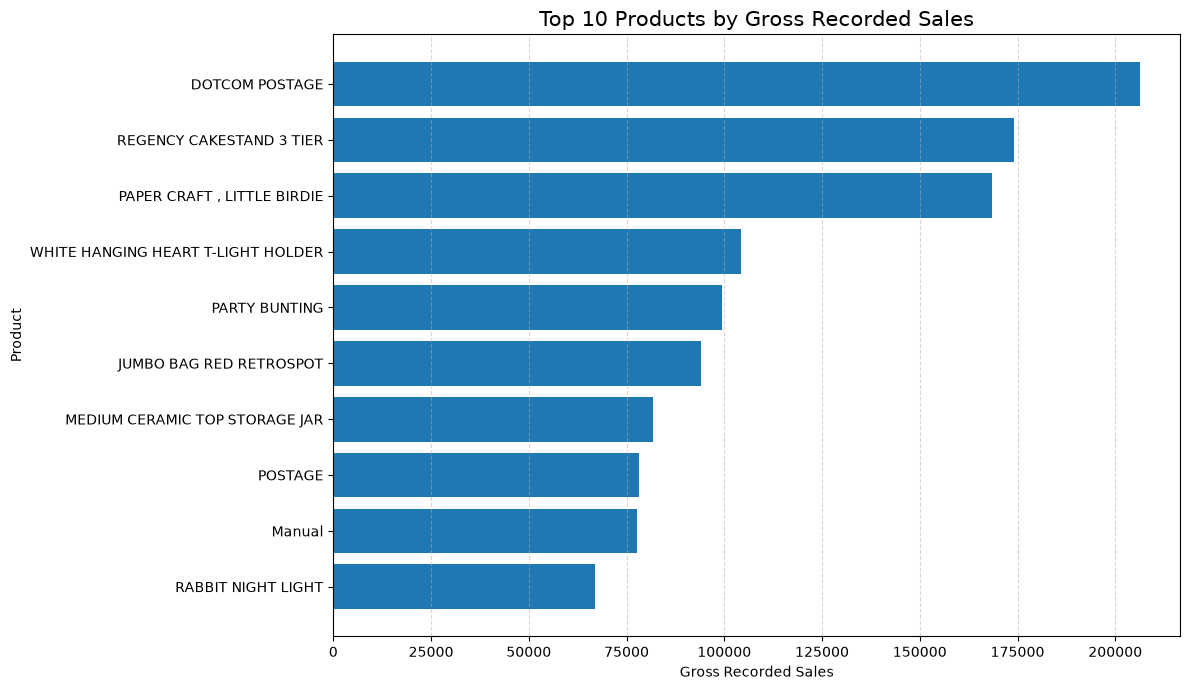

In [22]:

# Reverse the order so the highest-selling product appears at the top
plot_data = top_10_products.sort_values("Gross_Sales", ascending=True)

plt.figure(figsize=(12, 7))

plt.barh(
    plot_data["Description"],
    plot_data["Gross_Sales"]
)

plt.title("Top 10 Products by Gross Recorded Sales", fontsize=15)
plt.xlabel("Gross Recorded Sales")
plt.ylabel("Product")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()



## 18. Product Concentration and Validation

Product rankings help identify leading contributors, but they do not explain overall revenue concentration or establish inventory priorities.

We will calculate the combined sales share of the top 10 products and investigate products with unusually high unit volumes relative to their invoice counts. Service-related entries such as postage will be identified separately before making merchandise recommendations.


In [23]:

# Calculate the combined sales share of the top 10 products
top_10_sales = top_10_products["Gross_Sales"].sum()
total_sales = analysis_df["LineValue"].sum()

top_10_share = (top_10_sales / total_sales) * 100

print(f"Top 10 product sales: {top_10_sales:,.2f}")
print(f"Top 10 share of total sales: {top_10_share:.2f}%")

# Inspect the leading products by units sold
top_units_products = (
    product_sales
    .sort_values("Units_Sold", ascending=False)
    .head(10)
)

display(top_units_products)

# Inspect products appearing in only one distinct invoice
single_invoice_products = product_sales.loc[
    product_sales["Distinct_Orders"] == 1
].sort_values("Units_Sold", ascending=False)

display(single_invoice_products.head(10))


Top 10 product sales: 1,151,187.29
Top 10 share of total sales: 10.82%


,StockCode,Description,Gross_Sales,Units_Sold,Distinct_Orders
2590,23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995,1
2045,23166,MEDIUM CERAMIC TOP STORAGE JAR,81700.92,78033,247
2769,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,13814.01,54951,535
3761,85099B,JUMBO BAG RED RETROSPOT,94159.81,48371,2089
3773,85123A,WHITE HANGING HEART T-LIGHT HOLDER,104284.24,37580,2189
1051,22197,POPCORN HOLDER,34288.67,36749,803
370,21212,PACK OF 72 RETROSPOT CAKE CASES,21246.45,36396,1320
2875,84879,ASSORTED COLOUR BIRD ORNAMENT,58927.62,36362,1455
1951,23084,RABBIT NIGHT LIGHT,66870.03,30739,994
1327,22492,MINI PAINT SET VINTAGE,16937.82,26633,380


,StockCode,Description,Gross_Sales,Units_Sold,Distinct_Orders
2590,23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995,1
198,20914,SET/5 RED SPOTTY LID GLASS BOWLS,734.40,288,1
2006,23131,MISELTOE HEART WREATH CREAM,996.00,240,1
102,20725,LUNCH BAG RED SPOTTY,290.00,200,1
1732,22896,PEG BAG APPLE DESIGN,210.00,100,1
36,17001,HEAVENS SCENT FRAGRANCE OILS ASSTD,20.88,72,1
1122,22275,WEEKEND BAG VINTAGE ROSE PAISLEY,527.85,69,1
2762,82615,PINK MARSHMALLOW SCARF KNITTING KIT,91.80,36,1
1888,23035,DOORKNOB CERAMIC IVORY,52.20,36,1
1002,22145,CHRISTMAS CRAFT HEART STOCKING,63.00,30,1
